# 01 — Exploration of the UCI *Default of Credit Card Clients* data

Every number in this notebook is computed from the stored raw file by the project code.
Exploratory statistics use the **development training split only** (18,000 accounts) so that no
validation or test outcome informs a modelling decision. Data-quality checks use all 30,000 rows.

Run `creditlab fetch && creditlab prepare` before executing this notebook.

In [1]:
import json
import pandas as pd
from creditlab.utils.config import load_config
from creditlab.data.fetch import load_raw, provenance_path
from creditlab.data.validate import validate_raw
from creditlab.data.preprocess import load_processed
from creditlab.data.sql_analysis import connect, parse_sql_file, run_queries

pd.set_option("display.width", 140)
cfg = load_config()
prov = json.load(open(provenance_path(cfg)))
{k: prov[k] for k in ["dataset", "uci_id", "doi", "license", "rows", "content_identical_to_official_csv"]}

{'dataset': 'Default of Credit Card Clients',
 'uci_id': 350,
 'doi': '10.24432/C55S3H',
 'license': 'CC BY 4.0 (https://creativecommons.org/licenses/by/4.0/)',
 'rows': 30000,
 'content_identical_to_official_csv': True}

## 1. Schema and validation

In [2]:
raw = load_raw(cfg)
report = validate_raw(raw)
print(raw.shape)
{k: report[k] for k in ["rows", "n_features", "target_counts", "default_rate",
                        "accounts_with_any_negative_bill", "accounts_with_any_bill_over_limit",
                        "rows_in_duplicate_feature_groups", "duplicate_feature_groups_with_conflicting_labels"]}

(30000, 25)


{'rows': 30000,
 'n_features': 23,
 'target_counts': {0: 23364, 1: 6636},
 'default_rate': 0.2212,
 'accounts_with_any_negative_bill': 1930,
 'accounts_with_any_bill_over_limit': 3931,
 'rows_in_duplicate_feature_groups': 108,
 'duplicate_feature_groups_with_conflicting_labels': 21}

In [3]:
pd.DataFrame(report["undocumented_pay_codes"]).rename(columns=dict(zip([f"X{i}" for i in range(6, 12)],
    ["PAY_0 (Sep)", "PAY_2 (Aug)", "PAY_3 (Jul)", "PAY_4 (Jun)", "PAY_5 (May)", "PAY_6 (Apr)"])))

,PAY_0 (Sep),PAY_2 (Aug),PAY_3 (Jul),PAY_4 (Jun),PAY_5 (May),PAY_6 (Apr)
-2,2759,3782,4085,4348,4546,4895
0,14737,15730,15764,16455,16947,16286


## 2. SQL analysis (DuckDB)

In [4]:
con = connect(cfg, database=":memory:")
queries = parse_sql_file(cfg.path("sql_file"))
res = run_queries(con, queries)
[q.name for q in queries]

['overall_default_rate',
 'default_rate_by_pay0',
 'repayment_delay_patterns',
 'status_code_by_month',
 'status_transition_aug_to_sep',
 'bill_amount_distribution',
 'payment_to_bill_ratio',
 'credit_limit_deciles',
 'default_by_risk_bands',
 'data_quality_checks',
 'demographic_audit']

In [5]:
res['overall_default_rate']

,split,n_accounts,n_defaults,default_rate
0,ALL,30000,6636.0,0.2212
1,train,18000,3982.0,0.2212
2,validation,6000,1327.0,0.2212
3,test,6000,1327.0,0.2212


In [6]:
res['data_quality_checks']

,check_name,n
0,rows,30000
1,distinct IDs,30000
2,NULL cells (all columns),0
3,"target not in {0,1}",0
4,PAY_0 = -2 (undocumented),2759
5,PAY_0 = 0 (undocumented),14737
6,any status code 1 in PAY_2..PAY_6,28
7,"EDUCATION in {0,5,6} (undocumented)",345
8,MARRIAGE = 0 (undocumented),54
9,any negative bill amount,1930


In [7]:
res['default_rate_by_pay0']

,status_code,official_meaning,n_accounts,n_defaults,default_rate
0,-2,undocumented,1621,188.0,0.1160
1,-1,pay duly,3454,592.0,0.1714
2,0,undocumented,8870,1157.0,0.1304
3,1,delay 1 month(s),2217,758.0,0.3419
4,2,delay 2 month(s),1552,1089.0,0.7017
5,3,delay 3 month(s),201,149.0,0.7413
6,4,delay 4 month(s),52,33.0,0.6346
7,5,delay 5 month(s),13,6.0,0.4615
8,6,delay 6 month(s),5,2.0,0.4000
9,7,delay 7 month(s),3,2.0,0.6667


In [8]:
res['status_code_by_month']

,status_column,month,share_code_m2,share_code_m1,share_code_0,share_code_1,share_code_2,share_code_3plus,n_code_1
0,PAY_6,2005-04,0.1593,0.1956,0.5439,0.0000,0.0908,0.0104,0.0
1,PAY_5,2005-05,0.1479,0.1882,0.5669,0.0000,0.0858,0.0112,0.0
2,PAY_4,2005-06,0.1422,0.1942,0.5478,0.0001,0.1042,0.0116,2.0
3,PAY_3,2005-07,0.1334,0.2004,0.5242,0.0001,0.1292,0.0127,2.0
4,PAY_2,2005-08,0.1229,0.2053,0.5236,0.0009,0.1314,0.0158,17.0
5,PAY_0,2005-09,0.0901,0.1919,0.4928,0.1232,0.0862,0.0159,2217.0


In [9]:
res['repayment_delay_patterns']

,months_delayed_of_6,n_accounts,share_of_accounts,default_rate
0,0,11993,0.6663,0.1165
1,1,2625,0.1458,0.3021
2,2,1136,0.0631,0.3970
3,3,705,0.0392,0.5106
4,4,571,0.0317,0.5657
5,5,183,0.0102,0.5902
6,6,787,0.0437,0.6989


In [10]:
res['credit_limit_deciles']

,limit_decile,min_limit,max_limit,n_accounts,default_rate
0,1,10000,30000,1800,0.3561
1,2,30000,50000,1800,0.3039
2,3,50000,70000,1800,0.2872
3,4,70000,100000,1800,0.2539
4,5,100000,140000,1800,0.2250
5,6,140000,180000,1800,0.1878
6,7,180000,210000,1800,0.1761
7,8,210000,270000,1800,0.1600
8,9,270000,360000,1800,0.1472
9,10,360000,1000000,1800,0.1150


In [11]:
res['payment_to_bill_ratio']

,pay_to_bill_band,n_accounts,default_rate,median_ratio
0,0: no positive bill,564,0.3546,0.0000
1,"1: [0, 0.05)",5792,0.2738,0.0381
2,"2: [0.05, 0.10)",3048,0.2687,0.0655
3,"3: [0.10, 0.25)",1975,0.1863,0.1524
4,"4: [0.25, 0.50)",1575,0.1473,0.3538
5,"5: [0.50, 1.00)",2897,0.1505,0.7818
6,6: >= 1.00,2149,0.1587,1.1256


In [12]:
res['bill_amount_distribution']

,bill_column,min,p05,p25,median,p75,p95,max,mean,share_negative,share_zero
0,BILL_AMT1,-154973,0.0,3446.75,22352.5,67002.50,200901.30,964511,51070.5,0.0192,0.0658
1,BILL_AMT2,-30000,0.0,2878.25,21082.0,63838.25,194798.60,983931,49131.2,0.0225,0.0833
2,BILL_AMT3,-61506,0.0,2579.25,20082.5,59534.00,186888.80,1664089,46837.0,0.0213,0.0940
3,BILL_AMT4,-27490,0.0,2289.50,18966.5,54179.75,171573.30,891586,42979.0,0.0224,0.1053
4,BILL_AMT5,-61372,0.0,1770.00,17994.0,50009.50,164449.45,927171,40015.1,0.0223,0.1144
5,BILL_AMT6,-209051,0.0,1211.75,17097.5,49119.00,161526.75,961664,38765.4,0.0226,0.1331


In [13]:
res['default_by_risk_bands']

,utilisation_band,worst_delay_6m,n_accounts,default_rate
0,1: <10%,1 month,972,0.2634
1,1: <10%,2 months,930,0.3280
2,1: <10%,3+ months,155,0.6387
3,1: <10%,no delay,4724,0.1304
4,2: 10-50%,1 month,13,0.1538
5,2: 10-50%,2 months,1037,0.4417
6,2: 10-50%,3+ months,149,0.6913
7,2: 10-50%,no delay,2639,0.0682
8,3: 50-90%,1 month,8,0.1250
9,3: 50-90%,2 months,1259,0.4940


### Audit-only aggregate view of sensitive attributes
Reported with sample sizes for the research audit. These fields are **not** model inputs and are never used in policy rules.

In [14]:
res['demographic_audit']

,attribute,code_value,n_accounts,default_rate
0,AGE_BAND,21-29,5764,0.2266
1,AGE_BAND,30-39,6830,0.2025
2,AGE_BAND,40-49,3834,0.2350
3,AGE_BAND,50+,1572,0.2494
4,EDUCATION,0,9,0.0000
5,EDUCATION,1,6314,0.1889
6,EDUCATION,2,8428,0.2424
7,EDUCATION,3,2966,0.2444
8,EDUCATION,4,74,0.0541
9,EDUCATION,5,178,0.0787


## 3. Figures

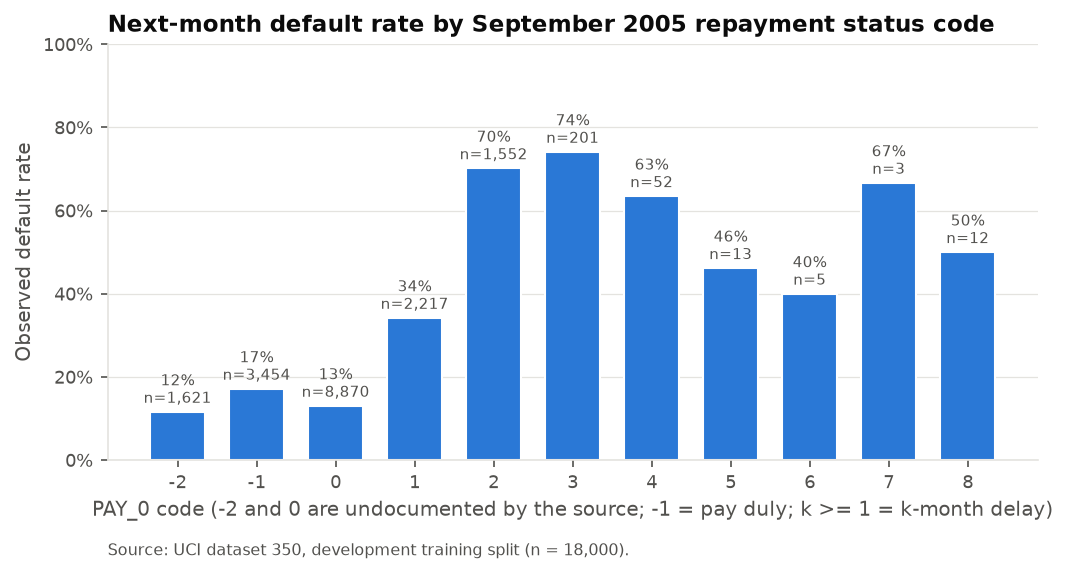

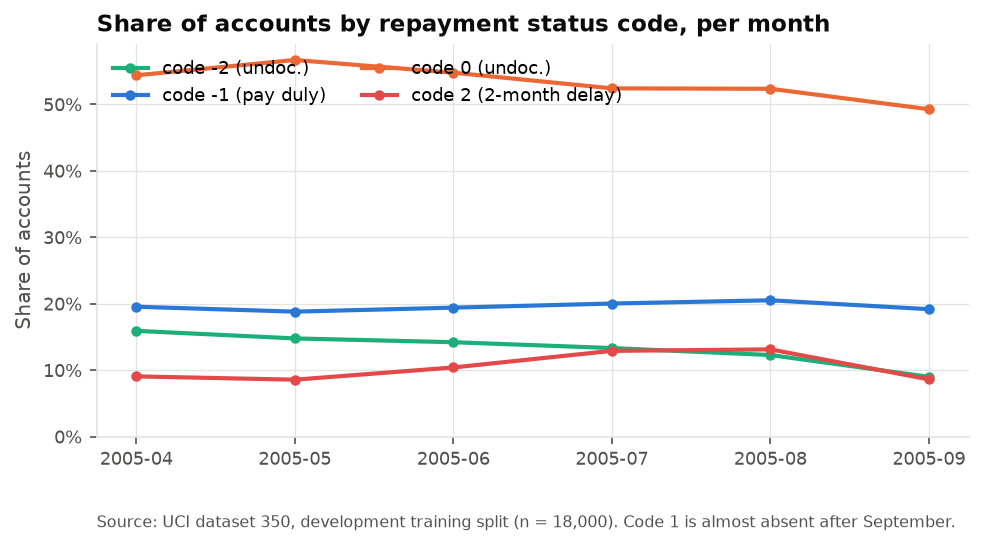

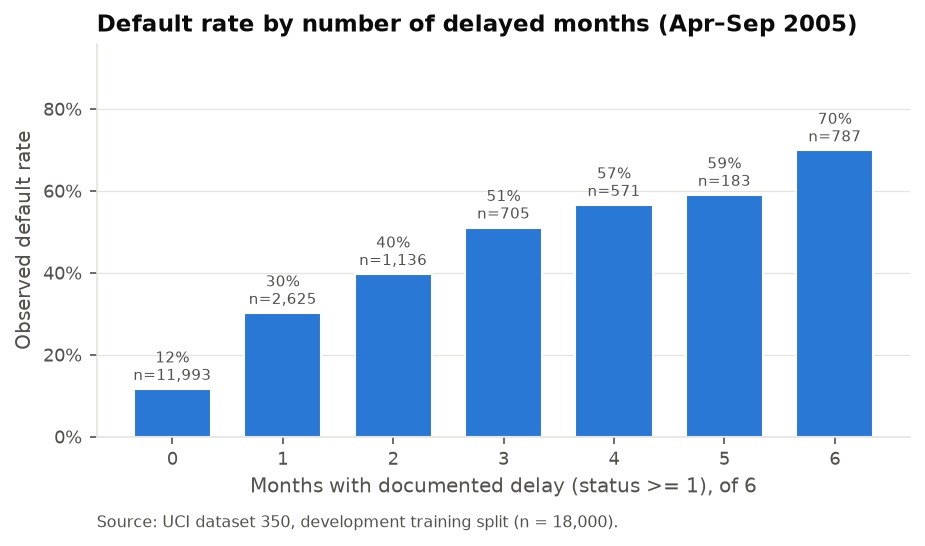

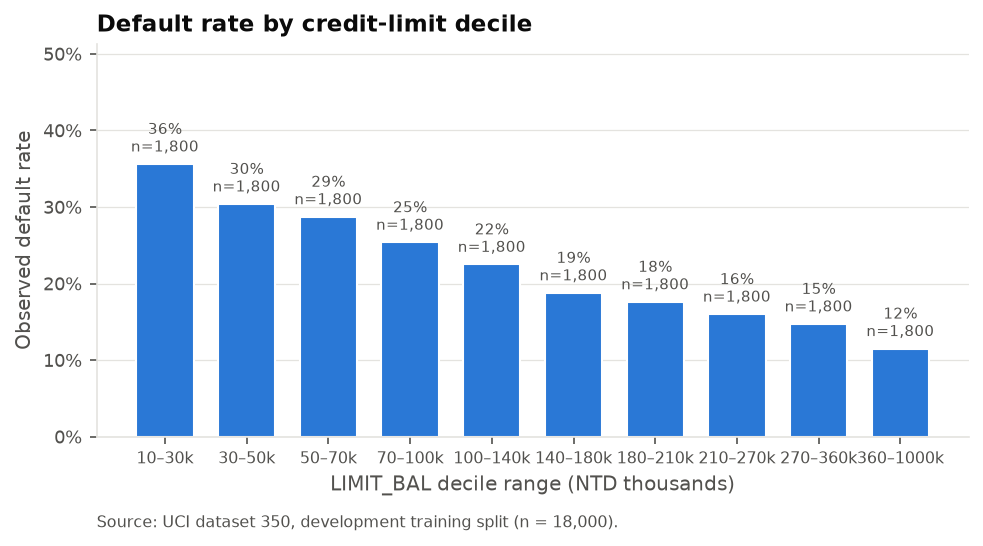

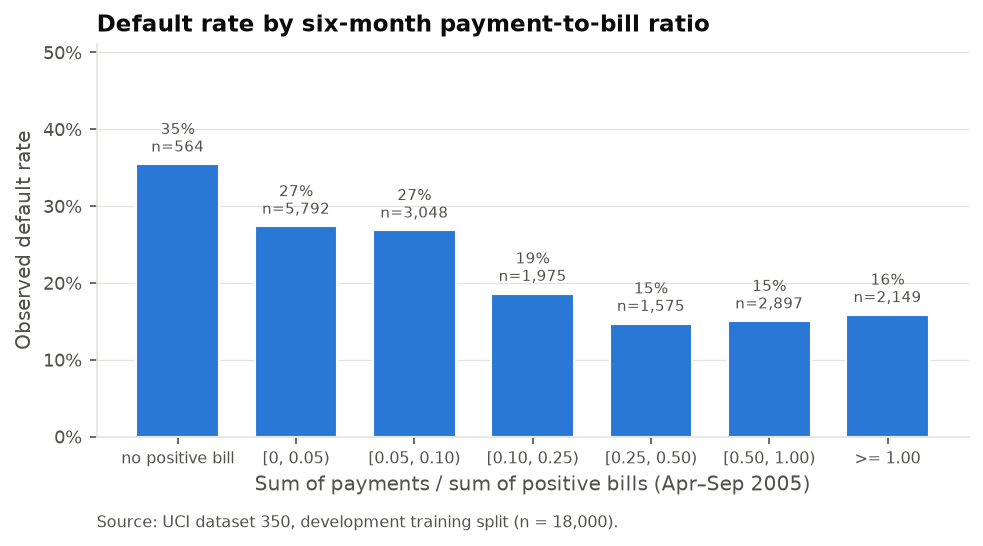

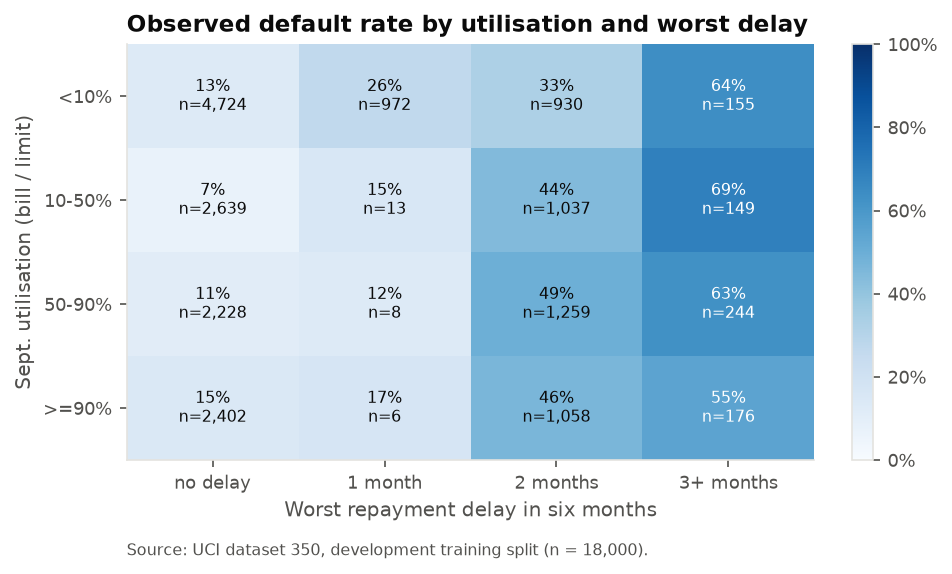

In [15]:
from IPython.display import Image, display
for name in ["eda_default_by_pay0", "eda_status_codes_by_month", "eda_default_by_months_delayed",
             "eda_default_by_limit_decile", "eda_default_by_pay_to_bill", "eda_risk_band_heatmap"]:
    display(Image(filename=str(cfg.artifacts / "figures" / f"{name}.png")))

## 4. Written analysis

**Outcome.** 6,636 of 30,000 accounts (22.1%) defaulted on the October 2005 payment. The split is
stratified, so train, validation and test each sit within 0.02 percentage points of that rate.

**Repayment status is the dominant observed signal.** In the training split the September status
code separates default rates sharply. Codes -2, -1 and 0 have default rates of 12–17%; a one-month
delay has 34%; a two-month delay has 70%. Default rates rise steadily with the number of months
(of six) that carry a documented delay.

**Coding anomalies, documented and not "fixed".** The source dictionary documents -1 (pay duly)
and 1–9 (months of delay) only, yet codes -2 and 0 cover 66.9% of all 180,000 month-records (13.6% and 53.3%).
Code 1 appears for about 12% of accounts in September but almost never in April–August
(zero accounts in April and May). This suggests the coding scheme differed between the most recent
month and earlier months, so the six status columns may not be strictly comparable. The models
therefore treat the codes as categories (logistic regression) or as ordered values that trees can
split at any code (XGBoost), and never interpret -2 or 0 as a specific behaviour.

**Balances and limits.** Default rates fall steadily from 36% in the lowest credit-limit decile
to 12% in the highest. Credit limits are themselves an outcome of past lending decisions, so this
is an association within an already-selected portfolio, not a causal effect of limits.
1,930 accounts have at least one negative bill (a credit balance), and 3,931 have at least one bill
above their limit. Both are kept as recorded.

**Payment behaviour.** Accounts that repaid less than 10% of their positive six-month billings
default at about 27%, versus about 15% (14.7–15.9% across bands) for accounts repaying at least a quarter. Accounts with no
positive bill in six months default at 35%. That small group (n = 564 in training) includes
inactive accounts, and their elevated rate is an observed pattern whose cause the data cannot
explain.

**Duplicates.** 108 rows belong to groups with identical feature vectors (distinct IDs). 21 of these
groups carry conflicting labels, showing irreducible noise for identical observed histories.
Rows are kept because IDs are distinct clients.

**Limitations visible already.** One observation window (Apr–Sep 2005) and a single outcome month
make a chronological out-of-time test impossible. The cohort consists of existing cardholders, not
applicants. There are no observed LGD, EAD, revenue or macroeconomic variables.